# Lab: SQL-to-Python Cloud Notebook Workflow

## Scenario: Support Operations Resolution Time

You are working as a junior data analyst for a software company's customer support operations team. The support operations manager asks:

> Can you help us understand which support ticket categories took the longest to resolve during the last quarter, and whether any team or category may need closer review?

Use the provided `support_operations.db` database and complete the notebook using the process **Identify -> Assemble -> Execute -> Verify**.


## Platform Setup

Place `support_operations.db` in the same folder as this notebook.

- **Google Colab:** upload the database file to the runtime, or mount Google Drive and update `db_path`.
- **Posit Cloud:** upload the database file to the project workspace.
- **SageMaker Studio Lab:** upload the database file to your home directory.


## Step 1: Clarify the Support Operations Question

Answer these questions in your own words:

- What question are you trying to answer?
- What does "took the longest to resolve" mean in this context?
- What data do you need?
- What output would be useful to the support operations manager?
- What checks will help you verify the result?
- What claim should you avoid making unless the data supports it?

### Planning Note

**Business question:** Which support ticket categories, and which category-team combinations, took the longest on average to resolve for tickets **created during Q1 2026** (January 1 – March 31, 2026)? Does any team or category show a pattern worth closer review?

**What "took the longest to resolve" means:** the elapsed time in days between `created_date` and `resolved_date`, calculated as `julianday(resolved_date) - julianday(created_date)` and averaged per group. Only completed tickets count: `status IN ('Resolved', 'Closed')` with a non-null `resolved_date`. Open, In Progress, and Escalated tickets have no end date, so they're excluded.

**Analysis period:** tickets *created* from 2026-01-01 through 2026-03-31. The cohort is defined by creation date, so a ticket created in March and resolved in April still counts. The database also contains Q4 2025 tickets (from 2025-10-01), so the date filter matters.

**Data needed:**
- `tickets`: `ticket_id`, `status`, `created_date`, `resolved_date`, `category_id`, `team_id`
- `ticket_categories`: `category_id`, `category_name`
- `teams`: `team_id`, `team_name`

**Expected output:** one row per category-team group with `category_name`, `team_name`, `total_completed_tickets`, and `avg_resolution_days` (2 decimals), sorted by `avg_resolution_days` descending, plus a horizontal bar chart of the top groups.

**Verification checks:**
1. The date filter returns only tickets created in Q1 2026.
2. Only `Resolved` and `Closed` tickets with a non-null `resolved_date` are included, and the count of completed tickets excluded for a missing `resolved_date` is reported.
3. `total_completed_tickets` sums to the same number as an independent count of qualifying tickets, so the joins drop or duplicate nothing.
4. No negative resolution times (which would mean resolved before created).
5. Groups with fewer than 5 completed tickets are flagged as small samples.
6. The chart values match `top_resolution_df`.

**Claims to avoid unless the data supports them:**
- That a team is "performing poorly," or that a category or team *causes* delays. Average resolution time alone doesn't account for ticket priority, complexity, or workload.
- Treating a small-sample group (fewer than 5 tickets) as a reliable pattern.


## Step 2: Break Down the Workflow Plan

Address:

- Database connection
- Database inspection
- SQL query logic, including calculations, filters, grouping, and sorting
- DataFrame review
- Analysis approach
- Visualization
- Verification

### Workflow Plan

**Database connection:** Import `sqlite3`, `Path`, `pandas`, and `matplotlib`. Mount Google Drive and set `db_path` to `/content/drive/MyDrive/flatiron_sql_cloud_lab/support_operations.db`. Check that the file exists, connect, verify the required tables (`tickets`, `ticket_categories`, `teams`), and print a confirmation.

**Database inspection:** List all tables. Run `PRAGMA table_info` on the three needed tables to get exact column names. Check the distinct `status` values and the `created_date` range. `ticket_events` isn't needed, because resolution time uses `created_date` and `resolved_date` from `tickets`.

**SQL query logic:**
- **Joins:** `tickets` → `ticket_categories` on `category_id`; `tickets` → `teams` on `team_id`
- **Filters:** `status IN ('Resolved', 'Closed')`; `created_date >= '2026-01-01' AND created_date < '2026-04-01'`; `resolved_date IS NOT NULL`
- **Calculations:** `ROUND(AVG(julianday(resolved_date) - julianday(created_date)), 2)` as `avg_resolution_days`; `COUNT(ticket_id)` as `total_completed_tickets`
- **Grouping:** `category_name`, `team_name`
- **Sorting:** `avg_resolution_days DESC`
- Results load into `resolution_df`.

**DataFrame review:** `head()`, `shape`, `info()`, `isna().sum()`, and `describe()` to confirm structure, data types, missing values, and value ranges.

**Analysis approach:** Sort into `top_resolution_df` (top 10 by average days). Identify the longest group and its ticket count, flag groups with fewer than 5 tickets as limited evidence, and compare against `standard_resolution_days` for context.

**Visualization:** A horizontal bar chart of `top_resolution_df` with combined "Category – Team" labels, an x-axis in days, a title naming the metric and Q1 2026, and the longest group at the top.

**Verification:** Recount qualifying tickets independently, report completed tickets excluded for a missing `resolved_date`, check min/max and look for negative values, confirm the included date range, flag small samples, and confirm the chart matches the DataFrame.


## Step 3: Connect to the SQLite Database


In [1]:
# Import the tools needed for this workflow.
# sqlite3 connects Python to the SQLite database.
# pandas loads SQL results into DataFrames.
# matplotlib creates the chart.
# pathlib checks that the database file exists before connecting.
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


### Optional Google Colab Drive Setup

If you are using Google Colab and your database is stored in Google Drive, uncomment and run the cell below before creating the database connection. Then update `db_path` to the full Drive path for your database file.


In [2]:
# Google Colab only: uncomment and run this cell if your database is stored in Drive.
# This sets db_path to your Drive location. The connection cell below will use it.
from google.colab import drive
drive.mount('/content/drive')
db_path = "/content/drive/MyDrive/flatiron_sql_cloud_lab/support_operations.db"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Create the SQLite Connection


In [3]:
# db_path was set in the Colab Drive cell above, so it is not reassigned here.
# Reassigning it to "support_operations.db" would point at the empty runtime folder.

# Confirm the database file exists before connecting
if not Path(db_path).exists():
    raise FileNotFoundError(
        f"Could not find {db_path}. Upload the database file to this notebook's working directory, "
        "or update db_path to the correct location."
    )

conn = sqlite3.connect(db_path)

# Verify the tables this analysis needs. The category table is ticket_categories, not categories.
required_tables = {"tickets", "ticket_categories", "teams"}
existing_tables = set(pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type = 'table';", conn
)["name"])
missing_tables = required_tables - existing_tables
if missing_tables:
    raise ValueError(f"Missing required table(s): {missing_tables}")

print(f"Database connection created: {db_path}")
print(f"Required tables verified: {sorted(required_tables)}")

Database connection created: /content/drive/MyDrive/flatiron_sql_cloud_lab/support_operations.db
Required tables verified: ['teams', 'ticket_categories', 'tickets']


## Step 4: Inspect the Database Structure

List the database tables, then inspect the relevant tables before writing your main query.


In [4]:
# Inspect

# Change the table name and rerun this cell as needed.
# List every table in the database
tables_df = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table';", conn)
display(tables_df)

# Show columns for each table this analysis uses (ticket_events is not needed)
for table_name in ["tickets", "ticket_categories", "teams"]:
    print(f"\n--- {table_name} ---")
    display(pd.read_sql_query(f"PRAGMA table_info({table_name});", conn)[["name", "type"]])

# Check the exact status values and the created_date range before filtering
display(pd.read_sql_query(
    "SELECT status, COUNT(*) AS ticket_count FROM tickets GROUP BY status ORDER BY ticket_count DESC;", conn
))
display(pd.read_sql_query(
    "SELECT MIN(created_date) AS earliest_created, MAX(created_date) AS latest_created FROM tickets;", conn
))

,name
0,teams
1,agents
2,ticket_categories
3,customers
4,tickets
5,ticket_events



--- tickets ---


,name,type
0,ticket_id,INTEGER
1,customer_id,INTEGER
2,category_id,INTEGER
3,team_id,INTEGER
4,assigned_agent_id,INTEGER
5,created_date,TEXT
6,resolved_date,TEXT
7,status,TEXT
8,priority,TEXT
9,channel,TEXT



--- ticket_categories ---


,name,type
0,category_id,INTEGER
1,category_name,TEXT
2,category_group,TEXT
3,standard_resolution_days,REAL



--- teams ---


,name,type
0,team_id,INTEGER
1,team_name,TEXT
2,team_region,TEXT
3,manager_name,TEXT


,status,ticket_count
0,Resolved,290
1,Closed,81
2,In Progress,32
3,Open,29
4,Escalated,23


,earliest_created,latest_created
0,2025-10-01,2026-03-31


## Step 5: Plan Your SQL Query Before Running It

Complete this checklist using the table and column names you found.

| Query Need | Actual Table or Column Name |
|---|---|
| Main ticket table | `tickets` |
| Ticket ID column | `tickets.ticket_id` |
| Ticket status column | `tickets.status` |
| Created date column | `tickets.created_date` |
| Resolved date column | `tickets.resolved_date` |
| Category table, if separate | `ticket_categories` |
| Category ID column | `tickets.category_id` = `ticket_categories.category_id` |
| Category name column | `ticket_categories.category_name` |
| Team table, if separate | `teams` |
| Team ID column | `tickets.team_id` = `teams.team_id` |
| Team name column | `teams.team_name` |
| Date range for the last quarter | `created_date >= '2026-01-01' AND created_date < '2026-04-01'` |

**Which fields will you use to calculate resolution time?**
`created_date` and `resolved_date`: `julianday(resolved_date) - julianday(created_date)` gives elapsed days, averaged with `AVG()`.

**Which field will you use to filter resolved tickets?**
`status IN ('Resolved', 'Closed')`, plus `resolved_date IS NOT NULL`, since a duration can't be calculated without an end date. The other statuses (`Open`, `In Progress`, `Escalated`) are excluded.

**Which field or fields will you group by?**
`category_name` and `team_name`, to get the average for each category-team combination.

**Which field will you sort by?**
`avg_resolution_days`, descending, so the longest groups come first.

**What could go wrong if you choose the wrong date column or join column?**
- **Wrong date column:** filtering on `resolved_date` instead of `created_date` would change the cohort to "tickets resolved in Q1." That would drop slow tickets created in March and resolved in April, and add Q4 2025 tickets resolved in January, biasing the averages downward.
- **Wrong join column:** joining `ticket_categories` on `team_id` (or `teams` on `category_id`) would still run without error, because both are integers. But it would attach the wrong labels, so results would look valid while being completely wrong.
- **Wrong table name:** the category table is `ticket_categories`, not `categories`. The template's connection check would have failed on this.

## Step 6: Query Support Ticket Resolution Time with SQL

Write and run a query that calculates average resolution time by ticket category, team, or both.

Use this date range: `2026-01-01` through `2026-03-31`.


In [5]:
# Query

# Practice pattern: average resolution time by status (Q1 2026 completed tickets)
avg_resolution_practice_query = """
SELECT
    status,
    COUNT(ticket_id) AS ticket_count,
    ROUND(AVG(julianday(resolved_date) - julianday(created_date)), 2) AS avg_resolution_days
FROM tickets
WHERE status IN ('Resolved', 'Closed')
  AND created_date >= '2026-01-01' AND created_date < '2026-04-01'
  AND resolved_date IS NOT NULL
GROUP BY status;
"""
avg_resolution_practice_df = pd.read_sql_query(avg_resolution_practice_query, conn)
display(avg_resolution_practice_df)

# Main query: average resolution time by category and team for Q1 2026 completed tickets
resolution_query = """
SELECT
    c.category_name AS category_name,
    t.team_name AS team_name,
    COUNT(tk.ticket_id) AS total_completed_tickets,
    ROUND(AVG(julianday(tk.resolved_date) - julianday(tk.created_date)), 2) AS avg_resolution_days
FROM tickets AS tk
JOIN ticket_categories AS c
    ON tk.category_id = c.category_id
JOIN teams AS t
    ON tk.team_id = t.team_id
WHERE tk.status IN ('Resolved', 'Closed')
  AND tk.created_date >= '2026-01-01' AND tk.created_date < '2026-04-01'
  AND tk.resolved_date IS NOT NULL
GROUP BY
    c.category_name,
    t.team_name
ORDER BY avg_resolution_days DESC;
"""
resolution_df = pd.read_sql_query(resolution_query, conn)
display(resolution_df)

# Completed tickets excluded because resolved_date is missing
missing_resolved_date_query = """
SELECT
    COUNT(*) AS resolved_or_closed_tickets_missing_resolved_date
FROM tickets
WHERE status IN ('Resolved', 'Closed')
  AND created_date >= '2026-01-01' AND created_date < '2026-04-01'
  AND resolved_date IS NULL;
"""
missing_resolved_date_df = pd.read_sql_query(missing_resolved_date_query, conn)
missing_resolved_date_df

,status,ticket_count,avg_resolution_days
0,Closed,39,4.87
1,Resolved,132,5.82


,category_name,team_name,total_completed_tickets,avg_resolution_days
0,API Integration,Enterprise Support,9,17.56
1,Security Review,Enterprise Support,1,14.00
2,Security Review,Security Support,6,12.67
3,Feature Request,Enterprise Support,10,10.40
4,Feature Request,Product Support,10,9.80
5,Performance Issue,Product Support,12,7.42
6,API Integration,Platform Support,7,6.57
7,Bug Report,Product Support,12,5.67
8,Bug Report,Enterprise Support,12,5.50
9,Performance Issue,Platform Support,8,5.25


,resolved_or_closed_tickets_missing_resolved_date
0,1


## Step 7: Load and Review Results in Pandas

Run these checks after `resolution_df` has been created.


In [6]:
# Load and review
display(resolution_df.head())

print("Shape (rows, columns):", resolution_df.shape)

resolution_df.info()

print("\nMissing values per column:")
print(resolution_df.isna().sum())

resolution_df.describe()


,category_name,team_name,total_completed_tickets,avg_resolution_days
0,API Integration,Enterprise Support,9,17.56
1,Security Review,Enterprise Support,1,14.00
2,Security Review,Security Support,6,12.67
3,Feature Request,Enterprise Support,10,10.40
4,Feature Request,Product Support,10,9.80


Shape (rows, columns): (18, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   category_name            18 non-null     object 
 1   team_name                18 non-null     object 
 2   total_completed_tickets  18 non-null     int64  
 3   avg_resolution_days      18 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 708.0+ bytes

Missing values per column:
category_name              0
team_name                  0
total_completed_tickets    0
avg_resolution_days        0
dtype: int64


,total_completed_tickets,avg_resolution_days
count,18.00000,18.000000
mean,9.50000,6.385556
std,3.29438,4.773785
min,1.00000,0.830000
25%,8.25000,2.980000
50%,10.00000,5.375000
75%,12.00000,9.205000
max,14.00000,17.560000


## Step 8: Analyze the Results

Identify the category/team combinations with the longest average resolution time.


In [7]:
# Analyze

# Top 10 category-team groups by average resolution time
top_resolution_df = resolution_df.sort_values(
    by="avg_resolution_days",
    ascending=False
).head(10).reset_index(drop=True)

# Flag small samples (fewer than 5 completed tickets) as limited evidence
top_resolution_df["sample_note"] = top_resolution_df["total_completed_tickets"].apply(
    lambda n: "Small sample (<5)" if n < 5 else "OK"
)

# Context: compare each group's average to its category's standard resolution benchmark
benchmarks = pd.read_sql_query(
    "SELECT category_name, standard_resolution_days FROM ticket_categories;", conn
)
top_resolution_df = top_resolution_df.merge(benchmarks, on="category_name", how="left")
top_resolution_df["days_over_standard"] = (
    top_resolution_df["avg_resolution_days"] - top_resolution_df["standard_resolution_days"]
).round(2)

# Combined label for the chart
top_resolution_df["category_team"] = (
    top_resolution_df["category_name"] + " - " + top_resolution_df["team_name"]
)

top_resolution_df

,category_name,team_name,total_completed_tickets,avg_resolution_days,sample_note,standard_resolution_days,days_over_standard,category_team
0,API Integration,Enterprise Support,9,17.56,OK,6.0,11.56,API Integration - Enterprise Support
1,Security Review,Enterprise Support,1,14.00,Small sample (<5),8.0,6.00,Security Review - Enterprise Support
2,Security Review,Security Support,6,12.67,OK,8.0,4.67,Security Review - Security Support
3,Feature Request,Enterprise Support,10,10.40,OK,7.0,3.40,Feature Request - Enterprise Support
4,Feature Request,Product Support,10,9.80,OK,7.0,2.80,Feature Request - Product Support
5,Performance Issue,Product Support,12,7.42,OK,5.5,1.92,Performance Issue - Product Support
6,API Integration,Platform Support,7,6.57,OK,6.0,0.57,API Integration - Platform Support
7,Bug Report,Product Support,12,5.67,OK,5.0,0.67,Bug Report - Product Support
8,Bug Report,Enterprise Support,12,5.50,OK,5.0,0.50,Bug Report - Enterprise Support
9,Performance Issue,Platform Support,8,5.25,OK,5.5,-0.25,Performance Issue - Platform Support


### Analysis Notes

Answer:

- Which category or category-team combination had the longest average resolution time?
- How many resolved tickets were included for that category or team?
- Is the ticket count large enough to treat the pattern as meaningful?
- What additional information would help explain the result?

**Which category-team combination had the longest average resolution time?**
**API Integration – Enterprise Support**, at **17.56 days** on average, the longest of all 18 groups.

**How many resolved tickets were included?**
**9** completed tickets (status `Resolved` or `Closed`, created in Q1 2026, with a non-null `resolved_date`).

**Is the ticket count large enough to treat the pattern as meaningful?**
Partly. Nine tickets clears the 5-ticket threshold, so this is a **signal worth review**, but it's still a small group, and a few unusually long tickets could inflate the average. Two context points strengthen it:
- It runs **11.56 days over** the API Integration standard of 6.0 days (about 2.9×).
- The **same category handled by Platform Support** averages 6.57 days across 7 tickets, close to the standard. So the long average isn't explained by the category alone.

The second-longest group, **Security Review – Enterprise Support (14.00 days), is based on 1 ticket**. That's a single data point, not a pattern, and shouldn't be treated as a finding. Account Cancellation – Enterprise Support (4 tickets) is also below the threshold.

**What additional information would help explain the result?**
- **`priority`** and **`reopened_count`** in `tickets`: whether these Enterprise integration tickets were more critical or reopened more often.
- **`ticket_events`**: time spent in each stage (for example, waiting on the customer vs. actively worked), which the overall duration hides.
- **`assigned_agent_id` with `agents.role_level`**: whether workload or staffing differs.
- **The median and the spread of individual ticket durations**, to see whether one or two outlier tickets drive the 17.56-day average.


## Step 9: Visualize the Results

Create a chart that clearly communicates the main comparison.


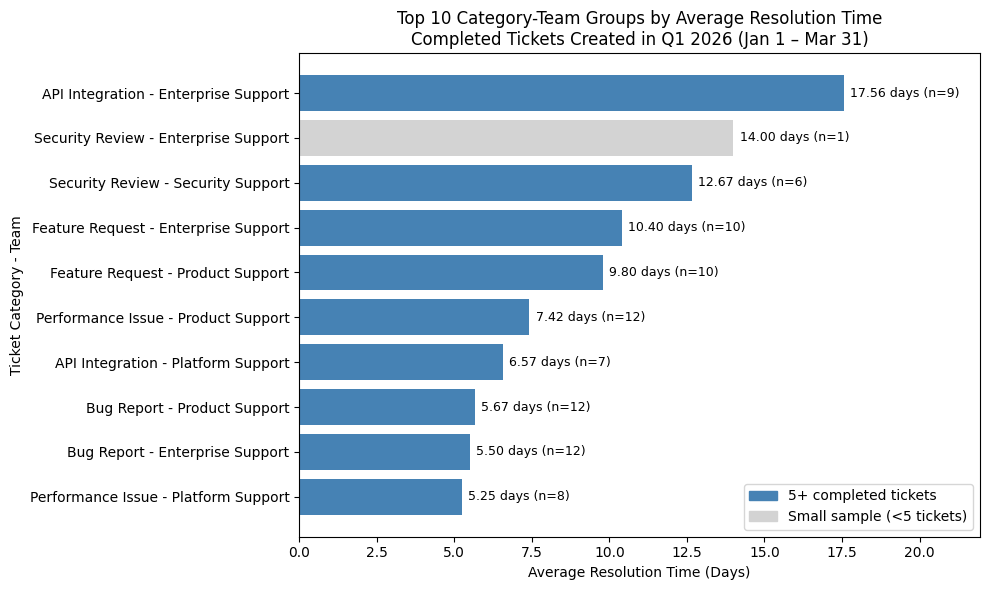

In [8]:
# Chart
plt.figure(figsize=(10, 6))

# Highlight small-sample groups so the chart doesn't overstate them
bar_colors = [
    "lightgray" if note != "OK" else "steelblue"
    for note in top_resolution_df["sample_note"]
]

bars = plt.barh(
    top_resolution_df["category_team"],
    top_resolution_df["avg_resolution_days"],
    color=bar_colors
)

# Label each bar with its average and ticket count, so values can be checked against the DataFrame
for bar, days, n in zip(bars, top_resolution_df["avg_resolution_days"],
                        top_resolution_df["total_completed_tickets"]):
    plt.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
             f"{days:.2f} days (n={n})", va="center", fontsize=9)

plt.xlabel("Average Resolution Time (Days)")
plt.ylabel("Ticket Category - Team")
plt.title("Top 10 Category-Team Groups by Average Resolution Time\n"
          "Completed Tickets Created in Q1 2026 (Jan 1 – Mar 31)")
plt.xlim(0, top_resolution_df["avg_resolution_days"].max() * 1.25)
plt.gca().invert_yaxis()

# Legend explaining the gray bar
from matplotlib.patches import Patch
plt.legend(handles=[Patch(color="steelblue", label="5+ completed tickets"),
                    Patch(color="lightgray", label="Small sample (<5 tickets)")],
           loc="lower right")

plt.tight_layout()
plt.show()

## Step 10: Evaluate and Verify the Output

Verify that the workflow produced a trustworthy result.


In [9]:
# Verify

# Required code checks
print("Total completed tickets in resolution_df:", resolution_df["total_completed_tickets"].sum())
print("Min / max avg_resolution_days:",
      resolution_df["avg_resolution_days"].min(), "/", resolution_df["avg_resolution_days"].max())
print("Groups with negative average resolution time:")
display(resolution_df[resolution_df["avg_resolution_days"] < 0])

# Independent ticket-level check, pulled without any joins
ticket_check_df = pd.read_sql_query("""
SELECT
    ticket_id,
    created_date,
    resolved_date,
    status,
    julianday(resolved_date) - julianday(created_date) AS resolution_days
FROM tickets
WHERE status IN ('Resolved', 'Closed')
  AND created_date >= '2026-01-01' AND created_date < '2026-04-01'
  AND resolved_date IS NOT NULL;
""", conn)

checks = {
    "Ticket count matches without joins (none dropped or duplicated)":
        len(ticket_check_df) == resolution_df["total_completed_tickets"].sum(),
    "No duplicate ticket_ids":
        ticket_check_df["ticket_id"].is_unique,
    "All created dates within Q1 2026":
        ticket_check_df["created_date"].between("2026-01-01", "2026-03-31").all(),
    "Only Resolved/Closed statuses":
        set(ticket_check_df["status"]) <= {"Resolved", "Closed"},
    "No negative ticket-level resolution times":
        (ticket_check_df["resolution_days"] >= 0).all(),
    "No duplicate category-team groups":
        not resolution_df.duplicated(subset=["category_name", "team_name"]).any(),
    "Chart data matches DataFrame (top 10 sorted)":
        top_resolution_df["avg_resolution_days"].tolist()
        == resolution_df["avg_resolution_days"].head(10).tolist(),
}
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")

print("\nCompleted tickets excluded for missing resolved_date:",
      missing_resolved_date_df.iloc[0, 0])
print("Small-sample groups (<5 tickets):")
display(resolution_df[resolution_df["total_completed_tickets"] < 5])

# Outlier check for the top group: is the average driven by a few long tickets?
top_group_tickets = pd.read_sql_query("""
SELECT
    julianday(tk.resolved_date) - julianday(tk.created_date) AS resolution_days
FROM tickets AS tk
JOIN ticket_categories AS c ON tk.category_id = c.category_id
JOIN teams AS t ON tk.team_id = t.team_id
WHERE c.category_name = 'API Integration'
  AND t.team_name = 'Enterprise Support'
  AND tk.status IN ('Resolved', 'Closed')
  AND tk.created_date >= '2026-01-01' AND tk.created_date < '2026-04-01'
  AND tk.resolved_date IS NOT NULL;
""", conn)
print("\nAPI Integration - Enterprise Support, individual ticket durations (days):")
print(sorted(top_group_tickets["resolution_days"].tolist()))
print("Median:", top_group_tickets["resolution_days"].median())

Total completed tickets in resolution_df: 171
Min / max avg_resolution_days: 0.83 / 17.56
Groups with negative average resolution time:


,category_name,team_name,total_completed_tickets,avg_resolution_days


PASS  Ticket count matches without joins (none dropped or duplicated)
PASS  No duplicate ticket_ids
PASS  All created dates within Q1 2026
PASS  Only Resolved/Closed statuses
PASS  No negative ticket-level resolution times
PASS  No duplicate category-team groups
PASS  Chart data matches DataFrame (top 10 sorted)

Completed tickets excluded for missing resolved_date: 1
Small-sample groups (<5 tickets):


,category_name,team_name,total_completed_tickets,avg_resolution_days
1,Security Review,Enterprise Support,1,14.00
12,Account Cancellation,Enterprise Support,4,3.25



API Integration - Enterprise Support, individual ticket durations (days):
[3.0, 6.0, 9.0, 9.0, 13.0, 13.0, 13.0, 17.0, 75.0]
Median: 13.0


### Verification Notes

Address:

- Did the query use the actual table and column names?
- Did the query use the correct joins?
- Did the date filter match Q1 2026?
- Did the query include only resolved tickets?
- Did the resolution-time calculation make sense?
- Were there missing values, duplicates, small sample sizes, or unusual values?
- Did the chart match the DataFrame?
- Did your written conclusion stay within what the data supports?

**Did the query use the actual table and column names?**
Yes. All names came from the `PRAGMA table_info` inspection. The category table is `ticket_categories`; the template's connection check expected `categories` and would have failed, so it was corrected.

**Did the query use the correct joins?**
Yes. `tickets.category_id = ticket_categories.category_id` and `tickets.team_id = teams.team_id`. The joined result totals **171** completed tickets, identical to an independent count from `tickets` alone with no joins. So the joins neither dropped nor duplicated rows, and every `ticket_id` is unique.

**Did the date filter match Q1 2026?**
Yes. `created_date >= '2026-01-01' AND created_date < '2026-04-01'`. All included tickets were created between 2026-01-01 and 2026-03-31. The database also holds Q4 2025 tickets (from 2025-10-01), and those were correctly excluded.

**Did the query include only resolved tickets?**
Yes. Only `Resolved` (132) and `Closed` (39) tickets with a non-null `resolved_date` are included. `Open`, `In Progress`, and `Escalated` tickets are excluded. **1** Resolved/Closed ticket was excluded because its `resolved_date` is missing, so its duration can't be calculated.

**Did the resolution-time calculation make sense?**
Yes. `julianday(resolved_date) - julianday(created_date)` returns elapsed days. There are no negative values at either the ticket or group level, and group averages range from 0.83 to 17.56 days.

**Were there missing values, duplicates, small sample sizes, or unusual values?**
- **Missing values:** none in `resolution_df`. One completed ticket was excluded for a missing `resolved_date` (noted above).
- **Duplicates:** none at either the ticket or group level.
- **Small samples:** Security Review – Enterprise Support (**1 ticket**, ranked 2nd) and Account Cancellation – Enterprise Support (**4 tickets**) are limited evidence, not reliable patterns.
- **Outlier:** the top group's 9 tickets took 3, 6, 9, 9, 13, 13, 13, 17, and **75** days. One 75-day ticket raises the mean to 17.56, while the **median is 13.0**, and excluding that ticket gives a mean of **10.38**. The group remains the slowest relative to its benchmark, but the mean overstates the typical ticket.

**Did the chart match the DataFrame?**
Yes. The chart plots `top_resolution_df`, whose values are asserted equal to the top 10 rows of `resolution_df`. Each bar is labeled with its exact value and ticket count, and the 1-ticket group is shaded gray.

**Did the written conclusion stay within what the data supports?**
The conclusion reports averages, ticket counts, benchmark comparisons, and the outlier. It makes no claims about team performance or causes, because resolution time alone doesn't account for priority, complexity, customer response time, or workload.


## Step 11: Write a Supported Final Explanation

Include:

- The original question
- The main finding
- Evidence from your SQL-to-Python workflow
- One limitation or assumption
- One recommended next step for review

### Final Explanation

**Original question:** Which support ticket categories took the longest to resolve for tickets created during Q1 2026 (January 1 – March 31, 2026), and does any team or category need closer review?

**Main finding:** **API Integration tickets handled by Enterprise Support** had the longest average resolution time: **17.56 days across 9 completed tickets**, nearly three times the category's 6-day standard. The same category handled by Platform Support averaged **6.57 days** (7 tickets), close to standard. The next-slowest groups with enough tickets to be meaningful were Security Review – Security Support (12.67 days, 6 tickets) and Feature Request – Enterprise Support (10.40 days, 10 tickets).

**Evidence from the SQL-to-Python workflow:** A SQL query joined `tickets` to `ticket_categories` and `teams`, kept only `Resolved` and `Closed` tickets created in Q1 2026 with a recorded resolution date (171 tickets), and averaged `julianday(resolved_date) - julianday(created_date)` for each category-team group. The results were loaded into pandas, reviewed (`shape`, `info`, missing values, `describe`), ranked, compared against `standard_resolution_days`, charted, and verified. An independent count of 171 tickets confirmed the joins, and the checks found no negative durations and no duplicates.

**Limitation:** The 17.56-day average is inflated by **one 75-day ticket**. The group's median is **13.0 days**, and without that ticket the average is **10.38 days**. That's still well above the 6-day standard and above Platform Support's average, but the typical ticket took less time than the headline figure suggests. Also, with only 9 tickets, a few cases can move the average substantially. The second-ranked group (Security Review – Enterprise Support, 14.00 days) is based on **a single ticket** and isn't a reliable pattern. This analysis measures elapsed time only, so it doesn't show *why* tickets took longer. Priority, complexity, and time spent waiting on customers aren't accounted for.

**Recommended next step:** Review the 9 API Integration – Enterprise Support tickets individually, starting with the 75-day ticket, using `ticket_events`, `priority`, and `reopened_count`. That would show where the time was spent and whether the gap from Platform Support reflects more complex Enterprise integrations or a process issue worth addressing.


## Step 12: Reflect on the Workflow

Answer:

- What was the most important step in making your result trustworthy?
- What issue or challenge did you need to check, debug, or refine?
- How did Identify → Assemble → Execute → Verify help you complete the workflow?
- How could this workflow be applied in another context?
- What would you improve if you repeated this analysis?
- What cloud constraint did you encounter, and how did you manage it?

### Reflection

**What was the most important step in making the result trustworthy?**
Checking the individual ticket durations behind the top group. Every aggregate check passed (counts, joins, dates, no negatives), but the ticket-level view showed that one 75-day ticket pulled the average from about 10 days to 17.56. Without that step, the headline number would have overstated the typical resolution time by about 70%.

**What issue or challenge did I need to check, debug, or refine?**
- **Table name mismatch:** the setup code expected a table named `categories`, but the database uses `ticket_categories`. Inspecting the schema first caught this before it caused a failed connection check or a broken join.
- **Cloud path conflict:** the template's connection cell reset `db_path` to `"support_operations.db"`, which would have overwritten the Google Drive path and failed. I removed that line, so the Drive path set in the mount cell is used.
- **Small samples:** the second-ranked group was a single ticket, so I flagged groups under 5 tickets in both the table and the chart.

**How did Identify → Assemble → Execute → Verify help?**
- **Identify:** defining "resolution time," the Q1 *created* cohort, and the claims to avoid kept the analysis focused and the conclusions careful.
- **Assemble:** inspecting tables, columns, status values, and the date range before writing SQL caught the table name and the Q4 2025 data that needed filtering out.
- **Execute:** SQL did the filtering, joining, and aggregation; pandas handled review, ranking, benchmark comparison, and charting.
- **Verify:** independent recounts and ticket-level checks confirmed the joins and surfaced the outlier, which changed how the main finding is described.

**How could this workflow apply in another context?**
In **cybersecurity**, the same pattern measures mean time to remediate vulnerabilities by severity and team: join findings to asset and team tables, filter to closed findings in a period, average the time between detection and fix, then check for outliers and small groups before escalating. The same verification habits (independent counts, flagging small samples, checking the median against the mean) apply to any operational metric reported to a manager.

**What would I improve if I repeated this analysis?**
Report the **median alongside the mean** for every group from the start, and break results down by `priority`. Averages over small groups are sensitive to single outliers, and a critical-priority ticket shouldn't be compared directly with a low-priority one.

**What cloud constraint did I encounter, and how did I manage it?**
Files uploaded directly to a Colab runtime are deleted whenever the runtime resets. I stored `support_operations.db` in **Google Drive** and mounted Drive in the notebook, so the file persists across sessions. The trade-off is that Drive must be re-mounted (and access re-approved) after every restart, which is why the mount cell runs before the connection cell.

### Cloud Evidence

- **Platform:** Google Colab
- **Database storage:** Google Drive, at `/content/drive/MyDrive/flatiron_sql_cloud_lab/support_operations.db`, mounted with `drive.mount('/content/drive')`. The notebook itself is also stored in the same Drive folder.
- **Reproducibility:** the notebook was run from top to bottom after **Runtime → Restart session and run all**, with Drive re-mounted, and every cell completed without errors.
- **Cloud constraint managed:** the runtime's file storage is temporary, so the database is kept in Drive (persistent storage) and the code runs in the Colab runtime (temporary compute). The file-existence and required-table checks fail fast with a clear message if the file isn't reachable.

## Close the Database Connection


In [10]:
conn.close()
print("Database connection closed.")


Database connection closed.
